In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from scipy.ndimage import gaussian_filter

plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False

ds = pydicom.dcmread("test_data\\1-042.dcm")
x = ds.pixel_array.astype(np.uint16)
x

array([[44, 20, 31, ..., 21, 24,  4],
       [30, 22, 27, ..., 28, 12, 15],
       [22, 25, 30, ..., 18, 18, 27],
       ...,
       [13, 22, 26, ..., 25, 16, 27],
       [14,  6, 20, ..., 27, 24, 33],
       [ 4,  8, 29, ..., 23, 26, 23]], shape=(512, 512), dtype=uint16)

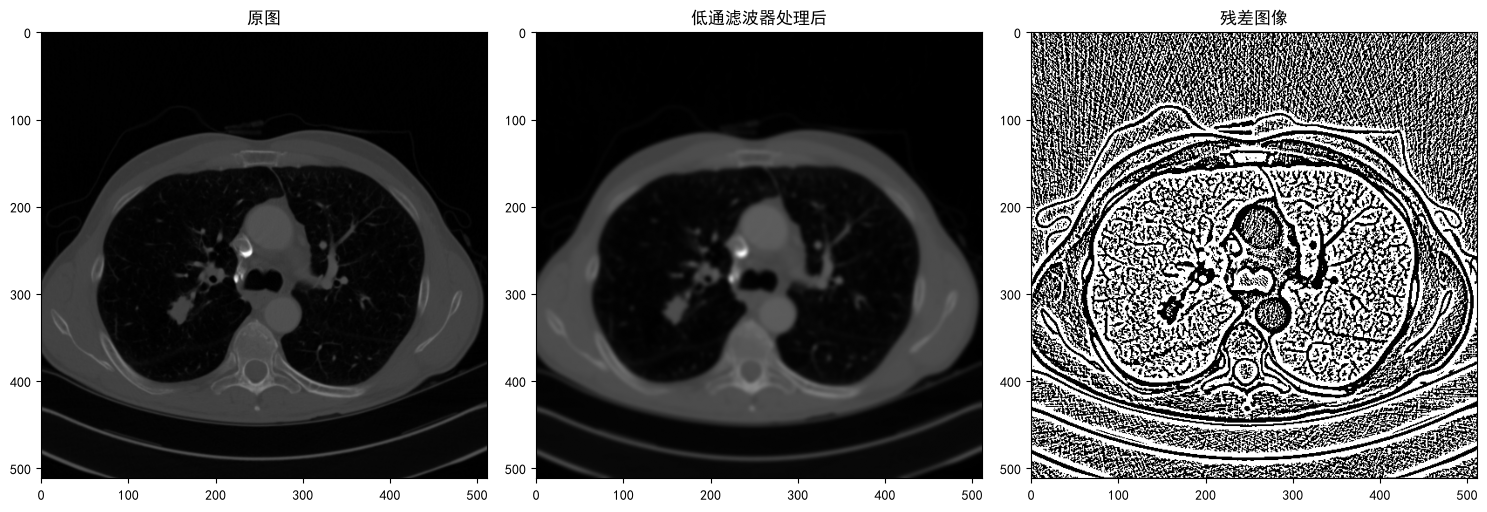

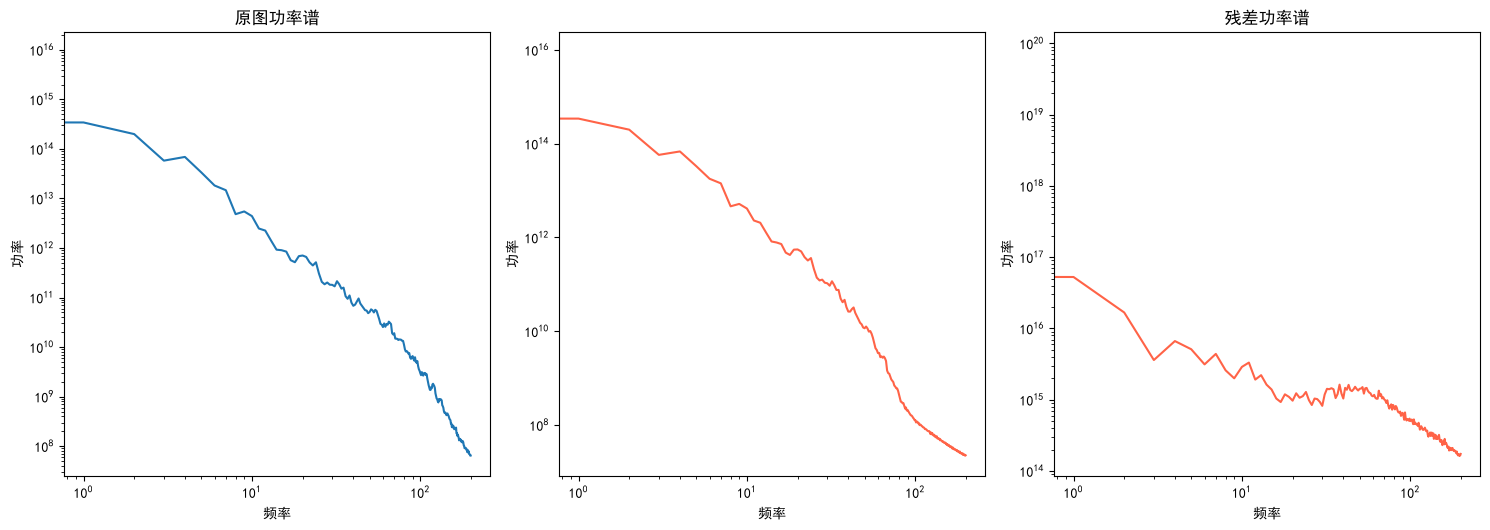

In [2]:
plt.figure(figsize=(15, 10))
# 空间冗余：低通(可预测) vs 残差(不可预测)
low = gaussian_filter(x, sigma=2)        # 平滑 = 邻居能猜出来的部分
high = x - low  
plt.subplot(2, 3, 1)
plt.imshow(x, cmap='gray'); plt.title("原图")                          # 残差 = 猜不出来的部分
plt.subplot(2, 3, 2)
plt.imshow(low, cmap='gray'); plt.title("低通滤波器处理后")
plt.subplot(2, 3, 3)
plt.imshow(high, cmap='gray'); plt.title("残差图像")
plt.tight_layout(); plt.show()


# 4. 径向功率谱（对数-对数）：原图 1/f² 衰减 vs 残差白化
def radial_power(img):
    cy, cx = img.shape[0]//2, img.shape[1]//2
    y, xx = np.ogrid[:img.shape[0], :img.shape[1]]
    r = np.sqrt((y-cy)**2+(xx-cx)**2).astype(int)
    pw = np.bincount(r.ravel(), weights=(np.abs(np.fft.fftshift(np.fft.fft2(img)))**2).ravel())
    cnt = np.bincount(r.ravel())
    return pw/cnt
plt.figure(figsize=(15, 10))
plt.subplot(2,3,1)
plt.loglog(radial_power(x)[:200], label='原图'); plt.xlabel('频率'); plt.ylabel('功率')
plt.title("原图功率谱")
plt.subplot(2,3,2)
plt.loglog(radial_power(low)[:200], color='tomato', label='低通'); plt.xlabel('频率'); plt.ylabel('功率')
plt.subplot(2,3,3)
plt.loglog(radial_power(high)[:200], color='tomato', label='残差'); plt.xlabel('频率'); plt.ylabel('功率')
plt.title("残差功率谱")
plt.tight_layout(); plt.show()

水平相邻相关系数 ρ = 0.9925
一阶熵 H0 = 8.87 | 残差熵 H_res = 6.77 | 空间冗余 ≈ 2.10 bit/像素


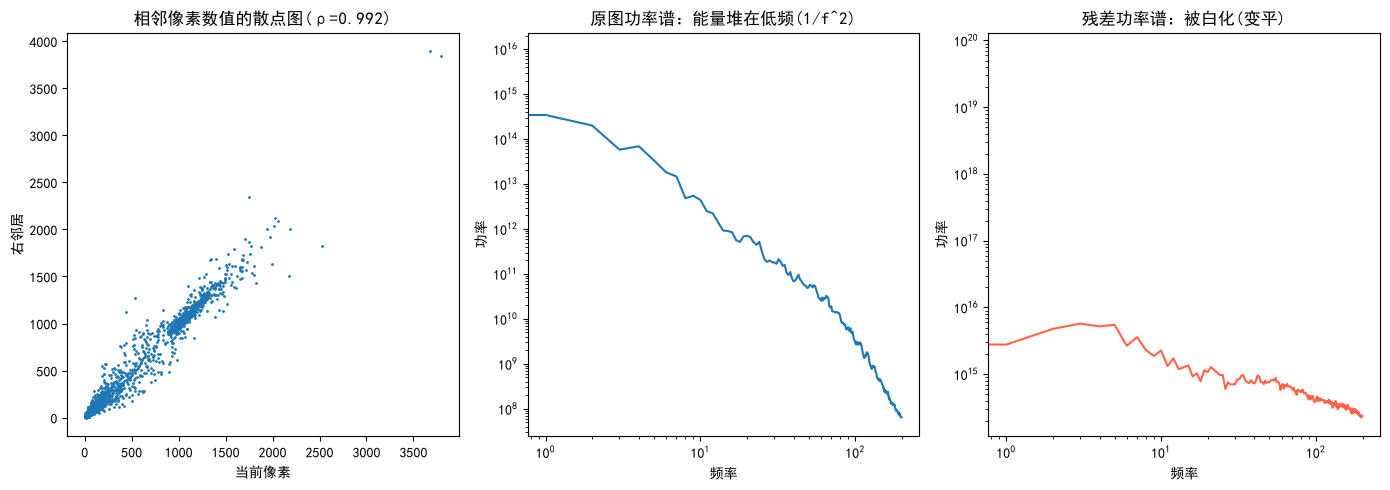

In [3]:
# 空间冗余
def entropy(a):
    v, c = np.unique(a, return_counts=True); p = c/c.sum()
    return -np.sum(p*np.log2(p))

# 1. 相关系数 ρ
rho = np.corrcoef(x[:,:-1].ravel(), x[:,1:].ravel())[0,1]
print(f"水平相邻相关系数 ρ = {rho:.4f}")

# 2. 熵降
res = x[:, 1:] - x[:, :-1]
print(f"一阶熵 H0 = {entropy(x):.2f} | 残差熵 H_res = {entropy(res):.2f} | 空间冗余 ≈ {entropy(x)-entropy(res):.2f} bit/像素")

# 3. 散点图（对角线 = 相关）
plt.figure(figsize=(14,5))
plt.subplot(1,3,1)
plt.scatter(x[:,:-1].ravel()[::50], x[:,1:].ravel()[::50], s=1)
plt.xlabel("当前像素"); plt.ylabel("右邻居"); plt.title(f"相邻像素数值的散点图(ρ={rho:.3f})")

# 4. 径向功率谱（对数-对数）：原图 1/f² 衰减 vs 残差白化
def radial_power(img):
    cy, cx = img.shape[0]//2, img.shape[1]//2
    y, xx = np.ogrid[:img.shape[0], :img.shape[1]]
    r = np.sqrt((y-cy)**2+(xx-cx)**2).astype(int)
    pw = np.bincount(r.ravel(), weights=(np.abs(np.fft.fftshift(np.fft.fft2(img)))**2).ravel())
    cnt = np.bincount(r.ravel())
    return pw/cnt

plt.subplot(1,3,2)
plt.loglog(radial_power(x)[:200], label='原图'); plt.xlabel('频率'); plt.ylabel('功率')
plt.title("原图功率谱：能量堆在低频(1/f^2)")
plt.subplot(1,3,3)
plt.loglog(radial_power(res)[:200], color='tomato', label='残差'); plt.xlabel('频率'); plt.ylabel('功率')
plt.title("残差功率谱：被白化(变平)")
plt.tight_layout(); plt.show()

自适应预测编码

C:\Users\Administrator\AppData\Local\Temp\ipykernel_2236\600017323.py:65: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_2236\600017323.py:66: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.savefig('adaptive_prediction_result.png', dpi=150, bbox_inches='tight')


已保存 adaptive_prediction_result.png
熵：原图 8.87 bit | 预测图 8.88 bit | 残差 6.27 bit
自适应预测带来的熵降：2.60 bit/像素


d:\ProgramData\Miniconda\envs\dcm_test\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


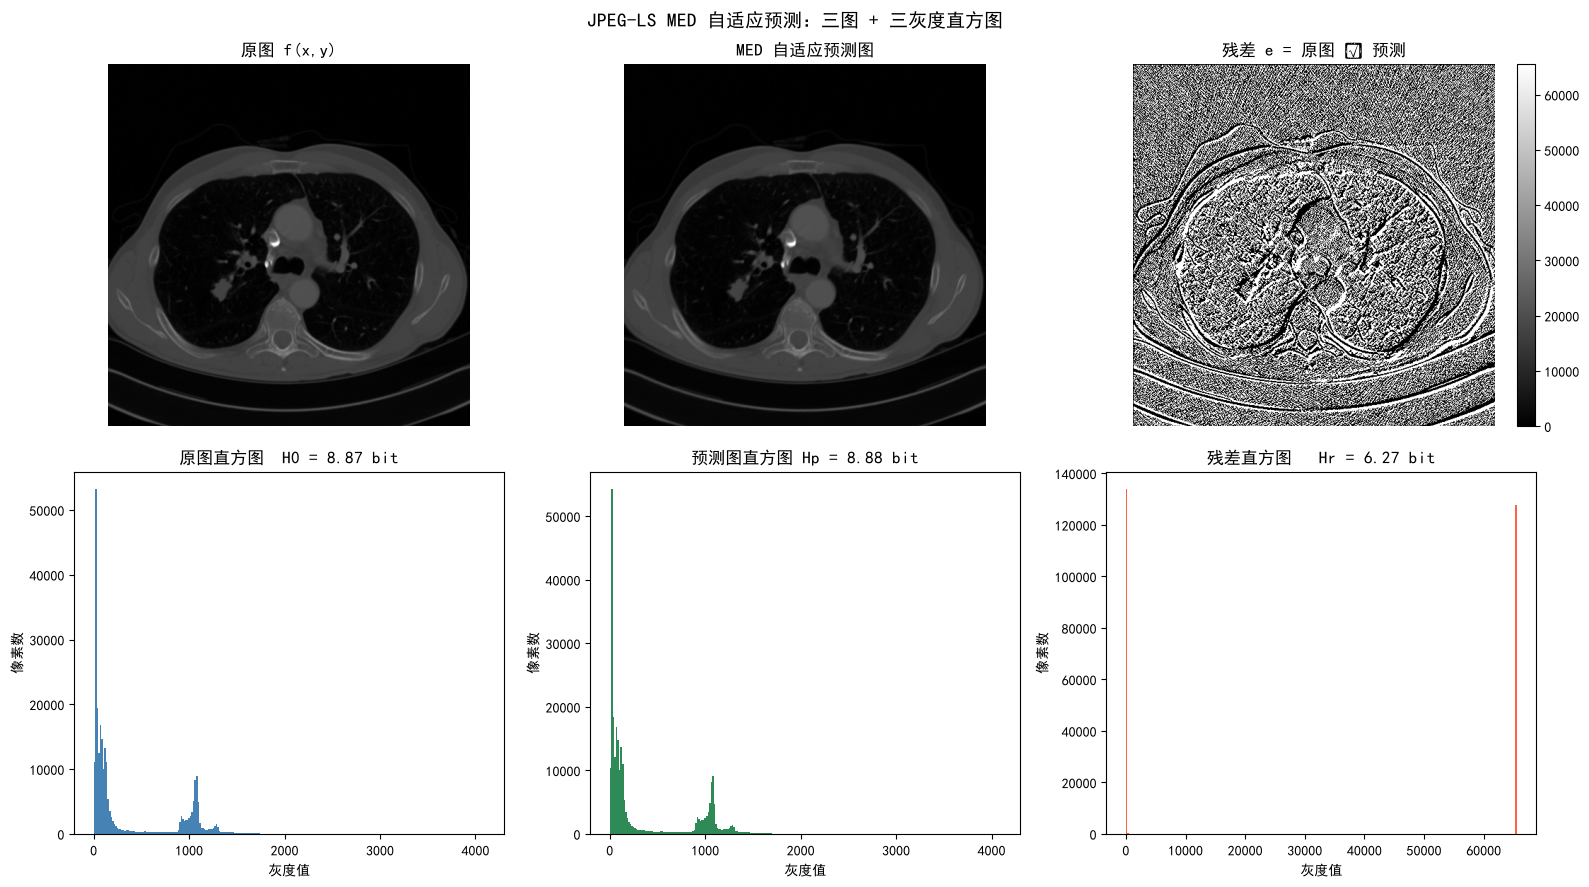

In [ ]:
# def med_predict(x):
#     """MED (Median Edge Detector) 因果预测器。
#     只用到当前像素左侧、上方、左上方的已解码邻居。
#     """
#     pred = np.empty_like(x)
#     # 第一行/第一列没有三个邻居，直接复制原值
#     pred[0, :] = x[0, :]
#     pred[:, 0] = x[:, 0]

#     # 内部像素
#     a = x[1:, :-1]   # 左  (West)
#     b = x[:-1, 1:]   # 上  (North)
#     c = x[:-1, :-1]  # 左上(North-West)

#     # MED 规则：
#     # - 边缘情况（c 是峰/谷）：取 a、b 中较接近的一个
#     # - 平滑情况：用 a + b - c（平面外推）
#     pred[1:, 1:] = np.where(
#         c >= np.maximum(a, b), np.minimum(a, b),
#         np.where(c <= np.minimum(a, b), np.maximum(a, b), a + b - c)
#     )
#     return pred


# pred = med_predict(x)
# residual = x - pred

# H0 = entropy(x)
# Hp = entropy(pred)
# Hr = entropy(residual)

# fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# # 第一行：图像
# titles_top = [
#     '原图 f(x,y)',
#     'MED 自适应预测图',
#     '残差 e = 原图 − 预测'
# ]
# arrays_top = [x, pred, residual]

# for ax, arr, title in zip(axes[0], arrays_top, titles_top):
#     im = ax.imshow(arr, cmap='gray')
#     ax.set_title(title)
#     ax.axis('off')
#     if '残差' in title:
#         plt.colorbar(im, ax=ax, fraction=0.046)

# # 第二行：各自灰度直方图
# titles_bottom = [
#     '原图直方图  H0 = %.2f bit' % H0,
#     '预测图直方图 Hp = %.2f bit' % Hp,
#     '残差直方图   Hr = %.2f bit' % Hr
# ]
# arrays_bottom = [x, pred, residual]
# colors = ['steelblue', 'seagreen', 'tomato']

# for ax, arr, title, color in zip(axes[1], arrays_bottom, titles_bottom, colors):
#     ax.hist(arr.ravel(), bins=256, color=color)
#     ax.set_title(title)
#     ax.set_xlabel('灰度值')
#     ax.set_ylabel('像素数')

# plt.suptitle('JPEG-LS MED 自适应预测：三图 + 三灰度直方图', fontsize=14)
# plt.tight_layout()
# plt.savefig('adaptive_prediction_result.png', dpi=150, bbox_inches='tight')

# print('已保存 adaptive_prediction_result.png')
# print('熵：原图 %.2f bit | 预测图 %.2f bit | 残差 %.2f bit' % (H0, Hp, Hr))
# print('自适应预测带来的熵降：%.2f bit/像素' % (H0 - Hr))

尴尬了，刚刚用uint16算，值溢出了

x dtype/shape      : uint16 (512, 512)
img dtype          : float64
residual dtype     : float64
residual min/max   : -1059.0 661.0
residual |.| 99.9分位: 269.0
NaN/inf 个数        : 0 0


C:\Users\Administrator\AppData\Local\Temp\ipykernel_53084\2097398409.py:72: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_53084\2097398409.py:73: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  plt.savefig('adaptive_prediction_result.png', dpi=150, bbox_inches='tight')


已保存 adaptive_prediction_result.png
熵：原图 8.87 bit | 预测图 8.88 bit | 残差 6.27 bit
自适应预测带来的熵降：2.60 bit/像素


d:\ProgramData\Miniconda\envs\dcm_test\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


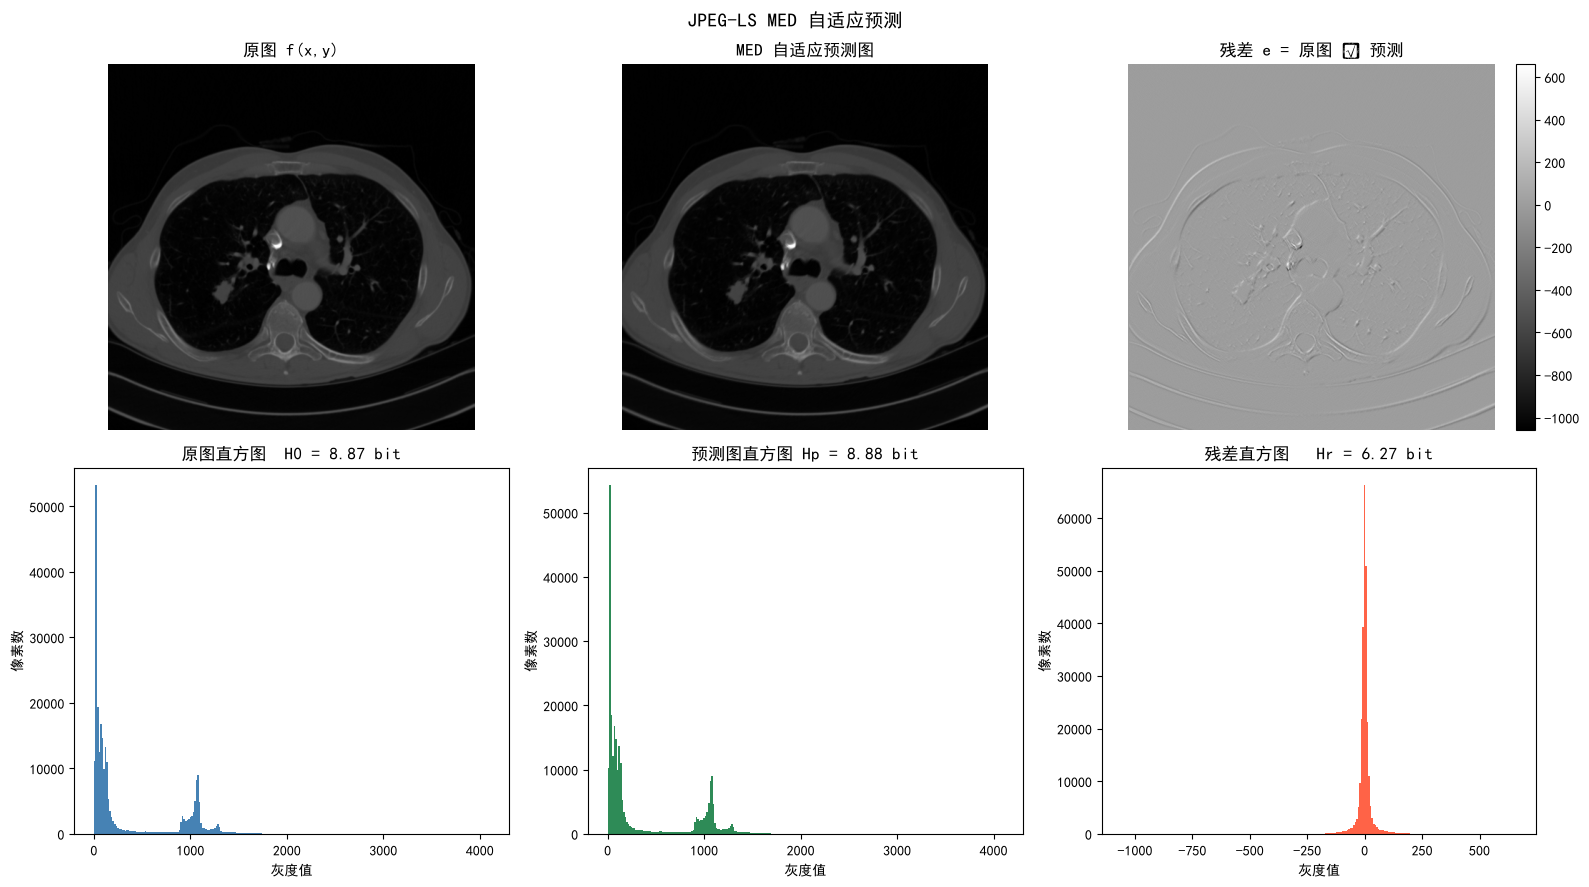

In [4]:
def med_predict(x):
    """MED (Median Edge Detector) 因果预测器。
    只用到当前像素左侧、上方、左上方的已解码邻居。
    """
    pred = np.empty_like(x)
    # 第一行/第一列没有三个邻居，直接复制原值
    pred[0, :] = x[0, :]
    pred[:, 0] = x[:, 0]

    # 内部像素
    a = x[1:, :-1]   # 左  (West)
    b = x[:-1, 1:]   # 上  (North)
    c = x[:-1, :-1]  # 左上(North-West)

    # MED 规则：
    # - 边缘情况（c 是峰/谷）：取 a、b 中较接近的一个
    # - 平滑情况：用 a + b - c（平面外推）
    pred[1:, 1:] = np.where(
        c >= np.maximum(a, b), np.minimum(a, b),
        np.where(c <= np.minimum(a, b), np.maximum(a, b), a + b - c)
    )
    return pred

img = x.astype(np.float64, copy=False)
pred = med_predict(img)
residual = img - pred

print('x dtype/shape      :', x.dtype, x.shape)
print('img dtype          :', img.dtype)
print('residual dtype     :', residual.dtype)
print('residual min/max   :', residual.min(), residual.max())
print('residual |.| 99.9分位:', np.percentile(np.abs(residual), 99.9))
print('NaN/inf 个数        :', np.isnan(residual).sum(), np.isinf(residual).sum())

H0 = entropy(img)
Hp = entropy(pred)
Hr = entropy(residual)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 第一行：图像
titles_top = [
    '原图 f(x,y)',
    'MED 自适应预测图',
    '残差 e = 原图 − 预测'
]
arrays_top = [img, pred, residual]

for ax, arr, title in zip(axes[0], arrays_top, titles_top):
    im = ax.imshow(arr, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
    if '残差' in title:
        plt.colorbar(im, ax=ax, fraction=0.046)

# 第二行：各自灰度直方图
titles_bottom = [
    '原图直方图  H0 = %.2f bit' % H0,
    '预测图直方图 Hp = %.2f bit' % Hp,
    '残差直方图   Hr = %.2f bit' % Hr
]
arrays_bottom = [img, pred, residual]
colors = ['steelblue', 'seagreen', 'tomato']

for ax, arr, title, color in zip(axes[1], arrays_bottom, titles_bottom, colors):
    ax.hist(arr.ravel(), bins=256, color=color)
    ax.set_title(title)
    ax.set_xlabel('灰度值')
    ax.set_ylabel('像素数')

plt.suptitle('JPEG-LS MED 自适应预测', fontsize=14)
plt.tight_layout()
plt.savefig('adaptive_prediction_result.png', dpi=150, bbox_inches='tight')

print('已保存 adaptive_prediction_result.png')
print('熵：原图 %.2f bit | 预测图 %.2f bit | 残差 %.2f bit' % (H0, Hp, Hr))
print('自适应预测带来的熵降：%.2f bit/像素' % (H0 - Hr))

编码冗余

linear fit: slope = -0.0107 | R2 = 0.9164
ratio test: mean P(k+1)/P(k) = 1.0135
saved geometric_test.png


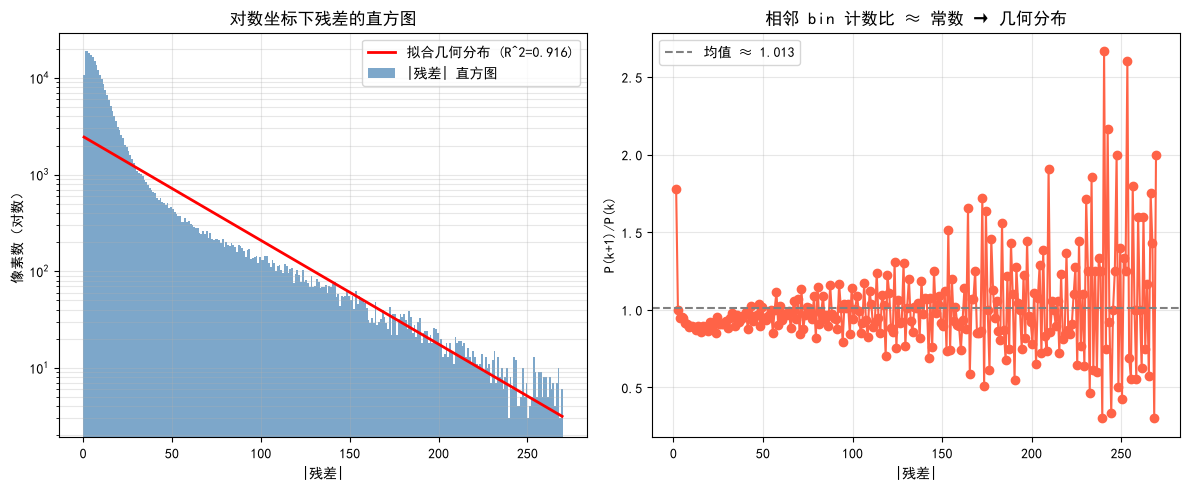

In [5]:
mag = np.abs(residual).round().astype(np.int64)

# 直方图（对数）
# rmax = int(mag.max())                     # 按实际最大值
rmax = int(np.percentile(mag, 99.9))    # 真数据有离群点就用这行，裁掉极端尾巴
counts, edges = np.histogram(mag, bins=np.arange(0, rmax + 2))
centers = (edges[:-1] + edges[1:]) / 2

# 只对非零 bin 拟合直线 log10(count) = a + b*center
mask = counts > 0
xc = centers[mask]
yc = np.log10(counts[mask])
b, a = np.polyfit(xc, yc, 1)          # 斜率 b, 截距 a
fit = 10 ** (a + b * centers)          # 回代
r = np.corrcoef(xc, yc)[0, 1]
r2 = r ** 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(centers, counts, width=1, color='steelblue', alpha=0.7, label='|残差| 直方图')
axes[0].plot(centers, fit, 'r-', lw=2,
             label='拟合几何分布 (R^2=%.3f)' % r2)
axes[0].set_yscale('log')
axes[0].set_xlabel('|残差|')
axes[0].set_ylabel('像素数（对数）')
axes[0].set_title('对数坐标下残差的直方图')
axes[0].legend()
axes[0].grid(alpha=0.3, which='both')

# 比值检验：相邻 bin 计数比应 ≈ 常数
ratios = counts[1:][counts[:-1] > 0] / counts[:-1][counts[:-1] > 0]
axes[1].plot(centers[1:][counts[:-1] > 0], ratios, 'o-', color='tomato')
axes[1].axhline(np.mean(ratios), ls='--', color='gray',
                label='均值 ≈ %.3f' % np.mean(ratios))
axes[1].set_xlabel('|残差|')
axes[1].set_ylabel('P(k+1)/P(k)')
axes[1].set_title('相邻 bin 计数比 ≈ 常数 → 几何分布')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('geometric_test.png', dpi=150, bbox_inches='tight')

print('linear fit: slope = %.4f | R2 = %.4f' % (b, r2))
print('ratio test: mean P(k+1)/P(k) = %.4f' % np.mean(ratios))
print('saved geometric_test.png')


Text(0.5, 1.0, '编码冗余：直方图不均，熵 H=8.9 < 16 bit')

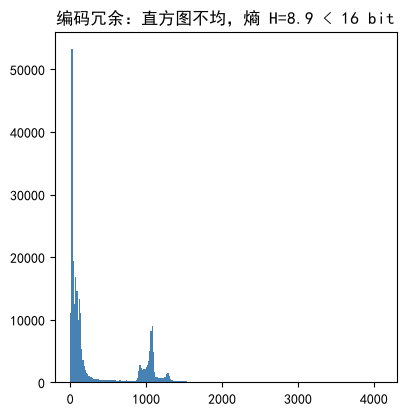

In [ ]:
# plt.figure(figsize=(15, 10))

# # 编码冗余：直方图
# vals, cnt = np.unique(x, return_counts=True)
# p = cnt / cnt.sum()
# H = -np.sum(p * np.log2(p))
# plt.subplot(2, 3, 1)
# plt.hist(x.ravel(), bins=256, color='steelblue')
# plt.title(f"编码冗余：直方图不均，熵 H={H:.1f} < 16 bit")

Golomb编码

In [54]:
print(residual.min(), residual.max(), type(residual))

-1059.0 661.0 <class 'numpy.ndarray'>


best_k = 4
fixed = 4.194 Mbit | golomb = 1.731 Mbit | ratio = 2.42
saved golomb_demo.png


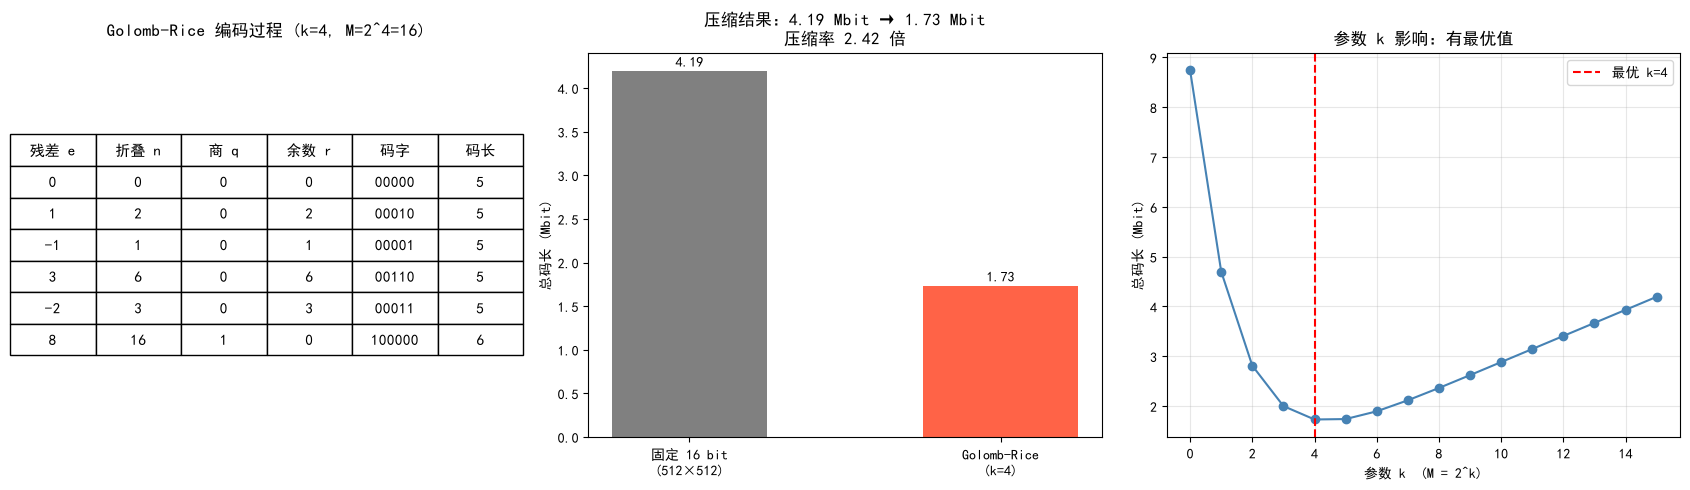

In [11]:
def fold(e):
    e = np.asarray(e, dtype=np.int64)
    return np.where(e >= 0, 2 * e, -2 * e - 1)   # 有符号残差 e -> 非负整数 n


def code_len(n, k):
    # Golomb-Rice：除数 M = 2^k
    # 商 q = n // M = n >> k，余数 r = n % M = n & (M-1)
    # 码长 = unary(q) 的 q+1 位 + k 位余数
    return (n >> k) + 1 + k


def encode_one(e, k):
    n = int(fold(np.int64(e)))       # n：折叠后的非负整数（不是除数）
    q = n >> k                       # 商
    r = n & ((1 << k) - 1)           # 余数
    return ('1' * q + '0') + format(r, '0%db' % k)

H, W = residual.shape
fixed_bits = H * W * 16

# 找最优 k（M = 2^k）
ks = np.arange(0, 16)
n_all = fold(residual.round().astype(np.int64))
totals = np.array([np.sum(code_len(n_all, k)) for k in ks])
best_k = int(ks[np.argmin(totals)])

# 整幅图压缩结果
golomb_bits = int(np.sum(code_len(n_all, best_k)))
ratio = fixed_bits / golomb_bits

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 面板1：编码过程示例表
axes[0].axis('off')
axes[0].set_title('Golomb-Rice 编码过程 (k=%d, M=2^%d=%d)' % (best_k, best_k, 2**best_k), pad=12)
rows = [('残差 e', '折叠 n', '商 q', '余数 r', '码字', '码长')]
for e in [0, 1, -1, 3, -2, 8]:
    n = int(fold(np.int64(e)))
    q = n >> best_k
    r = n & ((1 << best_k) - 1)
    code = encode_one(e, best_k)
    rows.append((str(e), str(n), str(q), str(r), code, str(len(code))))
t = axes[0].table(cellText=rows, loc='center', cellLoc='center')
t.auto_set_font_size(False)
t.set_fontsize(11)
t.scale(1, 1.9)

# 面板2：压缩结果对比
axes[1].bar([0, 1], [fixed_bits / 1e6, golomb_bits / 1e6],
            color=['gray', 'tomato'], width=0.5)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['固定 16 bit\n(%d×%d)' % (W, H), 'Golomb-Rice\n(k=%d)' % best_k])
axes[1].set_ylabel('总码长 (Mbit)')
axes[1].set_title('压缩结果：%.2f Mbit → %.2f Mbit\n压缩率 %.2f 倍' %
                  (fixed_bits / 1e6, golomb_bits / 1e6, ratio))
for i, v in enumerate([fixed_bits / 1e6, golomb_bits / 1e6]):
    axes[1].text(i, v + 0.05, '%.2f' % v, ha='center')

# 面板3：参数 k 的影响
axes[2].plot(ks, totals / 1e6, 'o-', color='steelblue')
axes[2].axvline(best_k, ls='--', color='red', label='最优 k=%d' % best_k)
axes[2].set_xlabel('参数 k  (M = 2^k)')
axes[2].set_ylabel('总码长 (Mbit)')
axes[2].set_title('参数 k 影响：有最优值')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('golomb_demo.png', dpi=150, bbox_inches='tight')
print('best_k = %d' % best_k)
print('fixed = %.3f Mbit | golomb = %.3f Mbit | ratio = %.2f' %
      (fixed_bits / 1e6, golomb_bits / 1e6, ratio))
print('saved golomb_demo.png')


上下文建模

每桶最优 k： [3, 3, 3, 3, 4, 4, 5, 6]
全局单 k：k=4 -> 1.726 Mbit
上下文建模： -> 1.575 Mbit
节省 0.151 Mbit (8.8%)
saved context_modeling.png


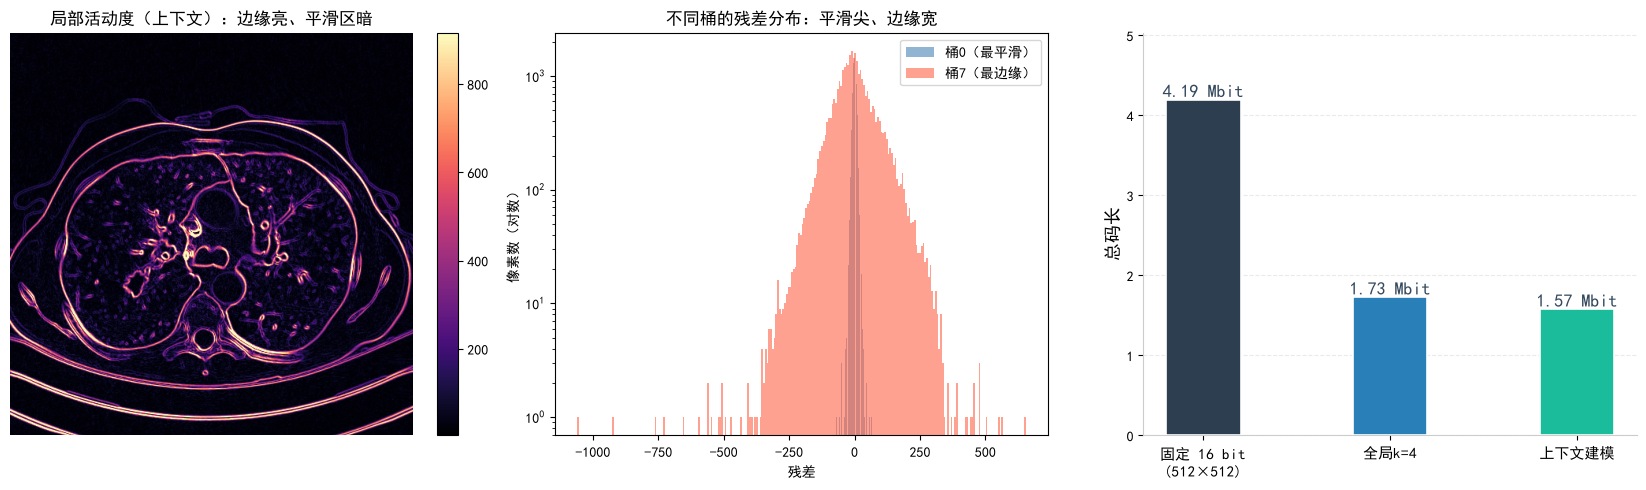

In [23]:
# ==================== 2. 局部活动度（上下文） ====================
a = img[1:, :-1]
b = img[:-1, 1:]
c = img[:-1, :-1]
activity = np.abs(a - b) + np.abs(b - c) + np.abs(c - a)   # 局部梯度幅值
res_int = residual[1:, 1:].round().astype(np.int64)

# ==================== 3. 按活动度分桶 ====================
B = 8
q = np.quantile(activity, np.linspace(0, 1, B + 1)[1:-1])
ctx = np.digitize(activity, q)                              # 0 .. B-1


# ==================== 4. Golomb-Rice 编码 ====================
def fold(e):
    e = np.asarray(e, dtype=np.int64)
    return np.where(e >= 0, 2 * e, -2 * e - 1)   # 有符号残差 e -> 非负整数 n


def code_len(n, k):
    # Golomb-Rice：除数 M = 2^k
    # 商 q = n // M = n >> k，余数 r = n % M = n & (M-1)
    return (n >> k) + 1 + k


ks = np.arange(0, 16)

# 全局单 k
n_all = fold(res_int)
global_total = int(min(code_len(n_all, k).sum() for k in ks))
best_global_k = int(min(ks, key=lambda k: code_len(n_all, k).sum()))

# 每桶各自最优 k
per_bucket_k = np.zeros(B, dtype=int)
context_total = 0
for bkt in range(B):
    mask = ctx == bkt
    n_b = fold(res_int[mask])
    bk = int(min(ks, key=lambda k: code_len(n_b, k).sum()))
    per_bucket_k[bkt] = bk
    context_total += int(code_len(n_b, bk).sum())

saving = global_total - context_total

# ==================== 5. 图 ====================
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 面板1：活动度图（边缘 = 高活动度）
im = axes[0].imshow(activity, cmap='magma', vmin=np.percentile(activity, 1),
                    vmax=np.percentile(activity, 99))
axes[0].set_title('局部活动度（上下文）：边缘亮、平滑区暗')
axes[0].axis('off')
plt.colorbar(im, ax=axes[0], fraction=0.046)

# 面板2：两个极端桶的残差分布（平滑 vs 边缘）
for bkt, lab, col in [(0, '桶0（最平滑）', 'steelblue'),
                      (B - 1, '桶%d（最边缘）' % (B - 1), 'tomato')]:
    mask = ctx == bkt
    axes[1].hist(res_int[mask], bins=256, color=col, alpha=0.6, log=True, label=lab)
axes[1].set_xlabel('残差')
axes[1].set_ylabel('像素数（对数）')
axes[1].set_title('不同桶的残差分布：平滑尖、边缘宽')
axes[1].legend()

# # 面板3：总码长对比
# axes[2].bar([0, 1, 2], [fixed_bits / 1e6, global_total / 1e6, context_total / 1e6], width=0.5)
# axes[2].set_xticks([0, 1, 2])
# axes[2].set_xticklabels(['固定 16 bit\n(%d×%d)' % (W, H), '全局单 k\n(k=%d)' % best_global_k, '上下文建模\n(8桶各调k)'])
# axes[2].set_ylabel('总码长 (Mbit)')
# # axes[2].set_title('上下文建模省 %.2f Mbit\n(%.1f%%)' %
# #                   (saving / 1e6, 100 * saving / global_total))
# for i, v in enumerate([global_total / 1e6, context_total / 1e6]):
#     axes[2].text(i, v + 0.02, '%.3f' % v, ha='center')

# plt.tight_layout()
# plt.savefig('context_modeling.png', dpi=150, bbox_inches='tight')

# print('每桶最优 k：', per_bucket_k.tolist())
# print('全局单 k：k=%d -> %.3f Mbit' % (best_global_k, global_total / 1e6))
# print('上下文建模： -> %.3f Mbit' % (context_total / 1e6))
# print('节省 %.3f Mbit (%.1f%%)' % (saving / 1e6, 100 * saving / global_total))
# print('saved context_modeling.png')

# ==================== 面板3：总码长对比（美化版 V2） ====================
# 1. 定义高级配色（深蓝，青蓝，薄荷绿）
colors = ['#2c3e50', '#2980b9', '#1abc9c']

# 计算数据
vals_mbit = [fixed_bits / 1e6, global_total / 1e6, context_total / 1e6]
labels = ['固定 16 bit\n(%d×%d)' % (W, H), '全局k=%d' % best_global_k, '上下文建模']
x_pos = np.arange(len(vals_mbit))

# 2. 绘制柱状图，缩小宽度 (width=0.4)，添加细微白边
bars = axes[2].bar(x_pos, vals_mbit, width=0.4, color=colors, edgecolor='white', linewidth=1.2, zorder=3)

# 3. 将数值标注在柱体外部上方，加上单位，字号放大
for bar, v in zip(bars, vals_mbit):
    axes[2].text(bar.get_x() + bar.get_width() / 2, v, 
                 '%.2f Mbit' % v, ha='center', va='bottom', # va='bottom' 让文字贴着柱体顶部向上生长
                 fontsize=13, fontweight='bold', color='#34495e') # 字号改大，颜色用深灰蓝

# 4. 美化坐标轴和网格
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(labels, fontsize=11) # X轴标签字号放大
axes[2].set_ylabel('总码长', fontsize=13)    # Y轴标签字号放大

# 动态调整Y轴上限，给外部文字留足空间
max_val = max(vals_mbit)
axes[2].set_ylim(0, max_val * 1.2) 

# 隐藏上方和右方的边框
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)
# 将左边和下边的边框变浅
axes[2].spines['left'].set_color('#CCCCCC')
axes[2].spines['bottom'].set_color('#CCCCCC')

# 使用浅色虚线网格，且在柱子下方
axes[2].yaxis.grid(True, linestyle='--', alpha=0.4, color='#CCCCCC', zorder=0)
axes[2].set_axisbelow(True)

# # 添加节省比例的副标题
# axes[2].set_title('压缩比 %.2f 倍' %
#                   (fixed_bits / context_total), fontsize=13, pad=15) # 标题字号放大

plt.tight_layout()
plt.savefig('context_modeling.png', dpi=150, bbox_inches='tight')

print('每桶最优 k：', per_bucket_k.tolist())
print('全局单 k：k=%d -> %.3f Mbit' % (best_global_k, global_total / 1e6))
print('上下文建模： -> %.3f Mbit' % (context_total / 1e6))
print('节省 %.3f Mbit (%.1f%%)' % (saving / 1e6, 100 * saving / global_total))
print('saved context_modeling.png')


解码 + 无损保真度验证 

In [24]:
# ==================== 解码 + 无损保真度验证 ====================

# 逆折叠（向量化）
def unfold(n):
    n = np.asarray(n, dtype=np.int64)
    return np.where(n % 2 == 0, n // 2, -(n + 1) // 2)

# 单个码字解码（课本约定：q 个 1 后跟一个 0）
def decode_one(code, k):
    q = 0
    i = 0
    while code[i] == '1':     # 数连续 1
        q += 1
        i += 1
    i += 1                    # 跳过结束的 0
    r = int(code[i:i + k], 2) # 读 k 位余数
    n = (q << k) + r          # 恢复 n
    return n // 2 if n % 2 == 0 else -(n + 1) // 2

# 编码（与解码同一约定）
def encode_one(e, k):
    n = int(np.where(e >= 0, 2 * e, -2 * e - 1))
    q = n >> k
    r = n & ((1 << k) - 1)
    return ('1' * q + '0') + format(r, '0%db' % k)

# ① 演示：几个残差编解码往返
print('残差 -> 码字 -> 解码：')
for e in [0, 1, -1, 3, -2, 8, 9]:
    c = encode_one(e, best_k)
    d = decode_one(c, best_k)
    print(f'  e={e:3d}  码字={c:<10s} 解码={d:3d}  {"对" if d == e else "错"}')

# ② 全图无损验证（向量化，快）
res_int = residual.round().astype(np.int64)
n = np.where(res_int >= 0, 2 * res_int, -2 * res_int - 1)   # 折叠
res_back = unfold(n)                                         # 展开
res_err = int(np.sum(res_back != res_int))

# ③ 重建图像并与原图对比
img_recon = pred + res_back
img_err = int(np.sum(img_recon != img))
img_max_err = float(np.max(np.abs(img_recon - img)))

print(f'\n残差往返：{res_int.size} 像素中 {res_err} 个不同（无损应为 0）')
print(f'图像重建：{img_err} 个像素与原图不同，最大误差 {img_max_err}')
print(f'保真度：{"100% 无损（逐像素完全一致，MSE=0）" if res_err == 0 and img_err == 0 else "有损！"}')

残差 -> 码字 -> 解码：
  e=  0  码字=00000      解码=  0  对
  e=  1  码字=00010      解码=  1  对
  e= -1  码字=00001      解码= -1  对
  e=  3  码字=00110      解码=  3  对
  e= -2  码字=00011      解码= -2  对
  e=  8  码字=100000     解码=  8  对
  e=  9  码字=100010     解码=  9  对

残差往返：262144 像素中 0 个不同（无损应为 0）
图像重建：0 个像素与原图不同，最大误差 0.0
保真度：100% 无损（逐像素完全一致，MSE=0）


In [14]:
import pandas as pd

# 残差取整
res_int = residual.round().astype(np.int64)

# 统计每个残差取值的频率和概率
unique, counts = np.unique(res_int, return_counts=True)
total = counts.sum()
prob = counts / total

# 折叠映射
def _fold(e):
    return np.where(e >= 0, 2 * e, -2 * e - 1)

# 使用前面得到的最优 k；如果没有 best_k 变量，当场重算
try:
    k = best_k
except NameError:
    ks = np.arange(0, 16)
    n_all = _fold(unique)
    k = int(min(ks, key=lambda kk: np.sum(counts * (((n_all >> kk) + 1 + kk)))))

# 生成完整编码表
rows = []
for e, cnt, p in zip(unique, counts, prob):
    n = int(_fold(np.int64(e)))       # n：折叠后的非负整数
    q = n >> k                        # 商
    r = n & ((1 << k) - 1)            # 余数
    code = ('1' * q + '0') + format(r, '0%db' % k)
    rows.append({
        '残差值': int(e),
        '频率': int(cnt),
        '概率': float(p),
        '折叠n': n,
        '商q': q,
        '余数r': r,
        '码字': code,
        '码长': len(code)
    })

df = pd.DataFrame(rows)
df = df.sort_values('频率', ascending=False).reset_index(drop=True)

# 输出到 Excel
df.to_excel('golomb_encoding_table.xlsx', index=False)

print('已保存 golomb_encoding_table.xlsx')
print(f'总像素数：{total}')
print(f'不同残差取值数：{len(df)}')
print('概率最高的 10 个残差：')
print(df.head(10).to_string(index=False))


已保存 golomb_encoding_table.xlsx
总像素数：262144
不同残差取值数：687
概率最高的 10 个残差：
 残差值    频率       概率  折叠n  商q  余数r    码字  码长
   0 10683 0.040752    0   0    0 00000   5
  -2  9529 0.036350    3   0    3 00011   5
  -1  9526 0.036339    1   0    1 00001   5
   1  9457 0.036076    2   0    2 00010   5
   2  9409 0.035892    4   0    4 00100   5
   3  9073 0.034611    6   0    6 00110   5
  -3  8916 0.034012    5   0    5 00101   5
  -4  8698 0.033180    7   0    7 00111   5
   4  8468 0.032303    8   0    8 01000   5
  -5  8192 0.031250    9   0    9 01001   5


C:\Users\Administrator\AppData\Local\Temp\ipykernel_2236\3366859767.py:12: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_2236\3366859767.py:12: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_2236\3366859767.py:12: UserWarning: Glyph 20002 (\N{CJK UNIFIED IDEOGRAPH-4E22}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_2236\3366859767.py:12: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_2236\3366859767.py:12: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()


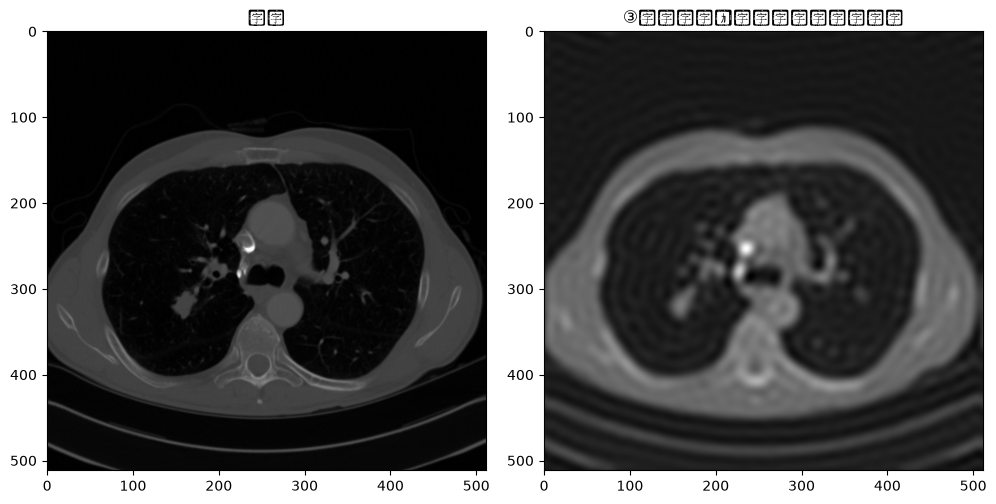

In [7]:
plt.figure(figsize=(15, 10))
# ③ 心理视觉冗余：频域只留低频，肉眼难辨
F = np.fft.fftshift(np.fft.fft2(x))
cy, cx = x.shape[0] // 2, x.shape[1] // 2
Y, X = np.ogrid[:x.shape[0], :x.shape[1]]
mask = (Y - cy)**2 + (X - cx)**2 <= 30**2  # 只保留低频圆盘
recon = np.fft.ifft2(np.fft.ifftshift(F * mask)).real
plt.subplot(2, 3, 4)
plt.imshow(x, cmap='gray'); plt.title("原图")
plt.subplot(2, 3, 5)
plt.imshow(recon, cmap='gray'); plt.title("③丢高频后：肉眼几乎看不出差别")
plt.tight_layout(); plt.show()